In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
#from IPython.display import display

import spacy

from tm.Mobile_App_Reviews_Classification_VSM import tf_idf_vectorizer

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [3]:
Path.cwd()

WindowsPath('C:/Users/Tea/PycharmProjects/nap-text-mining-nlp-bert/vezba/notebooks')

In [13]:
df=pd.read_csv(Path.cwd().parent / 'data' / 'bbc_news.csv')

In [14]:
df.head()


,title,pubDate,guid,link,description
0,Ukraine: Angry Zelensky vows to punish Russian...,"Mon, 07 Mar 2022 08:01:56 GMT",https://www.bbc.co.uk/news/world-europe-60638042,https://www.bbc.co.uk/news/world-europe-606380...,The Ukrainian president says the country will ...
1,War in Ukraine: Taking cover in a town under a...,"Sun, 06 Mar 2022 22:49:58 GMT",https://www.bbc.co.uk/news/world-europe-60641873,https://www.bbc.co.uk/news/world-europe-606418...,"Jeremy Bowen was on the frontline in Irpin, as..."
2,Ukraine war 'catastrophic for global food',"Mon, 07 Mar 2022 00:14:42 GMT",https://www.bbc.co.uk/news/business-60623941,https://www.bbc.co.uk/news/business-60623941?a...,One of the world's biggest fertiliser firms sa...
3,Manchester Arena bombing: Saffie Roussos's par...,"Mon, 07 Mar 2022 00:05:40 GMT",https://www.bbc.co.uk/news/uk-60579079,https://www.bbc.co.uk/news/uk-60579079?at_medi...,The parents of the Manchester Arena bombing's ...
4,Ukraine conflict: Oil price soars to highest l...,"Mon, 07 Mar 2022 08:15:53 GMT",https://www.bbc.co.uk/news/business-60642786,https://www.bbc.co.uk/news/business-60642786?a...,Consumers are feeling the impact of higher ene...


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42115 entries, 0 to 42114
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        42115 non-null  str  
 1   pubDate      42115 non-null  str  
 2   guid         42115 non-null  str  
 3   link         42115 non-null  str  
 4   description  42115 non-null  str  
dtypes: str(5)
memory usage: 1.6 MB


In [27]:
df.pubDate.str.rsplit(',').str[1]

0         07 Mar 2022 08:01:56 GMT
1         06 Mar 2022 22:49:58 GMT
2         07 Mar 2022 00:14:42 GMT
3         07 Mar 2022 00:05:40 GMT
4         07 Mar 2022 08:15:53 GMT
                   ...            
42110     03 Dec 2024 23:07:27 GMT
42111     03 Dec 2024 17:48:54 GMT
42112     03 Dec 2024 23:00:17 GMT
42113     04 Dec 2024 00:05:52 GMT
42114     04 Dec 2024 00:03:58 GMT
Name: pubDate, Length: 42115, dtype: object

In [32]:
df.pubDate=df.pubDate.str.split(' ').str[3]

In [37]:
df = df[df.pubDate == '2023']

In [39]:
df.info()

<class 'pandas.DataFrame'>
Index: 15043 entries, 12266 to 35941
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        15043 non-null  str   
 1   pubDate      15043 non-null  object
 2   guid         15043 non-null  str   
 3   link         15043 non-null  str   
 4   description  15043 non-null  str   
dtypes: object(1), str(4)
memory usage: 705.1+ KB


In [40]:
df=df.sample(n=1500,random_state=42)

In [42]:
df.info()

<class 'pandas.DataFrame'>
Index: 1500 entries, 23360 to 18088
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        1500 non-null   str   
 1   pubDate      1500 non-null   object
 2   guid         1500 non-null   str   
 3   link         1500 non-null   str   
 4   description  1500 non-null   str   
dtypes: object(1), str(4)
memory usage: 70.3+ KB


In [43]:
df.drop(columns='guid',inplace=True)

In [44]:
df.drop(columns='link',inplace=True)

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 1500 entries, 23360 to 18088
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        1500 non-null   str   
 1   pubDate      1500 non-null   object
 2   description  1500 non-null   str   
dtypes: object(1), str(2)
memory usage: 46.9+ KB


In [46]:
df.drop(columns='pubDate',inplace=True)

In [47]:
df['text']=df['title'] + '. ' + df['description']


In [48]:
df.text

23360    Children among 17 Britons dead or missing in I...
27171    Former PM Tony Blair was keen on Wimbledon FC ...
27003    Serbia protests: Anti-government demonstrators...
19627    Harry Kane: Top European clubs holding out for...
26773    Hamas hostages: Stories of the people taken fr...
                               ...                        
20255    Florida deputy jumps onto a speeding runaway b...
15646    Pentagon documents leak a risk to US national ...
19499    Climate records tumble, leaving Earth in uncha...
25217    Mum-to-be faces two-year nursery wait as deman...
18088    North America smoke: Is climate change fuellin...
Name: text, Length: 1500, dtype: str

In [50]:
df['text_lenght']=df.text.str.split( ).str.len()

In [52]:
df.text_lenght.describe()

count    1500.000000
mean       27.692667
std         5.151431
min        14.000000
25%        24.000000
50%        27.000000
75%        30.000000
max        51.000000
Name: text_lenght, dtype: float64

In [53]:
model=spacy.load('en_core_web_md')

In [54]:
proba=model('ja sam vukasin')

In [55]:
proba[0]

ja

In [80]:
def spacy_sredi_text(doc):
    ocisceni_tokeni=[]
    tokens=model(doc)
    for token in tokens:
        lema_lowwer=token.lemma_.lower()
        if token.is_punct or token.like_num or token.like_url:
            continue
        if token.is_stop and lema_lowwer!='not':
            continue
        ocisceni_tokeni.append(lema_lowwer)
    return ocisceni_tokeni

In [82]:
embedings=[]
for tekst in df['text']:
    reci=spacy_sredi_text(tekst)
    embedings.append(model(' '.join(reci)).vector)
embedings=np.array(embedings)
print(embedings.shape)

(1500, 300)


In [83]:
distance=1-cosine_similarity(embedings,embedings)

{'icoord': [[15.0, 15.0, 25.0, 25.0],
  [5.0, 5.0, 20.0, 20.0],
  [35.0, 35.0, 45.0, 45.0],
  [55.0, 55.0, 65.0, 65.0],
  [75.0, 75.0, 85.0, 85.0],
  [60.0, 60.0, 80.0, 80.0],
  [40.0, 40.0, 70.0, 70.0],
  [12.5, 12.5, 55.0, 55.0],
  [105.0, 105.0, 115.0, 115.0],
  [95.0, 95.0, 110.0, 110.0],
  [125.0, 125.0, 135.0, 135.0],
  [102.5, 102.5, 130.0, 130.0],
  [145.0, 145.0, 155.0, 155.0],
  [185.0, 185.0, 195.0, 195.0],
  [175.0, 175.0, 190.0, 190.0],
  [165.0, 165.0, 182.5, 182.5],
  [150.0, 150.0, 173.75, 173.75],
  [116.25, 116.25, 161.875, 161.875],
  [33.75, 33.75, 139.0625, 139.0625],
  [225.0, 225.0, 235.0, 235.0],
  [215.0, 215.0, 230.0, 230.0],
  [205.0, 205.0, 222.5, 222.5],
  [255.0, 255.0, 265.0, 265.0],
  [245.0, 245.0, 260.0, 260.0],
  [285.0, 285.0, 295.0, 295.0],
  [275.0, 275.0, 290.0, 290.0],
  [252.5, 252.5, 282.5, 282.5],
  [213.75, 213.75, 267.5, 267.5],
  [315.0, 315.0, 325.0, 325.0],
  [305.0, 305.0, 320.0, 320.0],
  [335.0, 335.0, 345.0, 345.0],
  [355.0, 355.0, 3

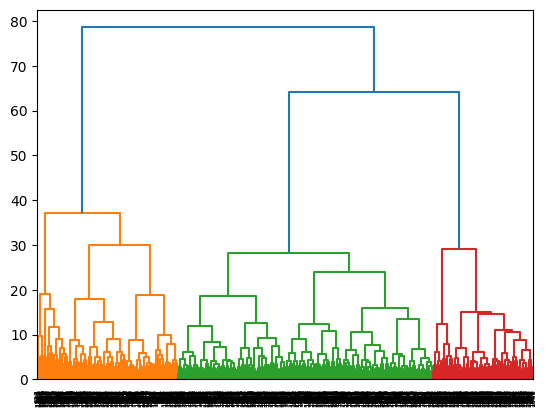

In [84]:
ward_linkuage=sch.linkage(distance,method='ward')
sch.dendrogram(ward_linkuage)

In [ ]:
#optimalan broj klastera ide od 2 do 8

In [85]:
dist_clipped=np.clip(distance,0,None)

In [86]:
for k in range(2,9):
    klasteri=sch.fcluster(ward_linkuage, t=k, criterion='maxclust')
    print(k,round(silhouette_score(dist_clipped,klasteri,metric='precomputed'),4))

2 0.1376
3 0.0674
4 0.0618
5 0.0613
6 0.0384
7 -0.0031
8 -0.0261


In [72]:
#definitivno najbolje je podeliti na 2 klastera ...

In [104]:
N_clusters=4

In [105]:
df['clusteri']=sch.fcluster(ward_linkuage,t=N_clusters,criterion='maxclust')

In [106]:
df.clusteri.value_counts()

clusteri
3    771
2    332
4    303
1     94
Name: count, dtype: int64

In [107]:
keywords_extractpr=TfidfVectorizer(tokenizer=spacy_sredi_text,token_pattern=None,ngram_range=(2,2),min_df=0.01,max_df=0.95)

In [108]:
def getkeyweards(cluster):
    tekst=df[df['clusteri']==cluster]['text']
    tf_idf=keywords_extractpr.fit_transform(tekst)
    proseci=tf_idf.mean(axis=0).A1
    reci=keywords_extractpr.get_feature_names_out()
    rezultat=pd.Series(proseci,index=reci)
    return rezultat.nlargest(10).items()

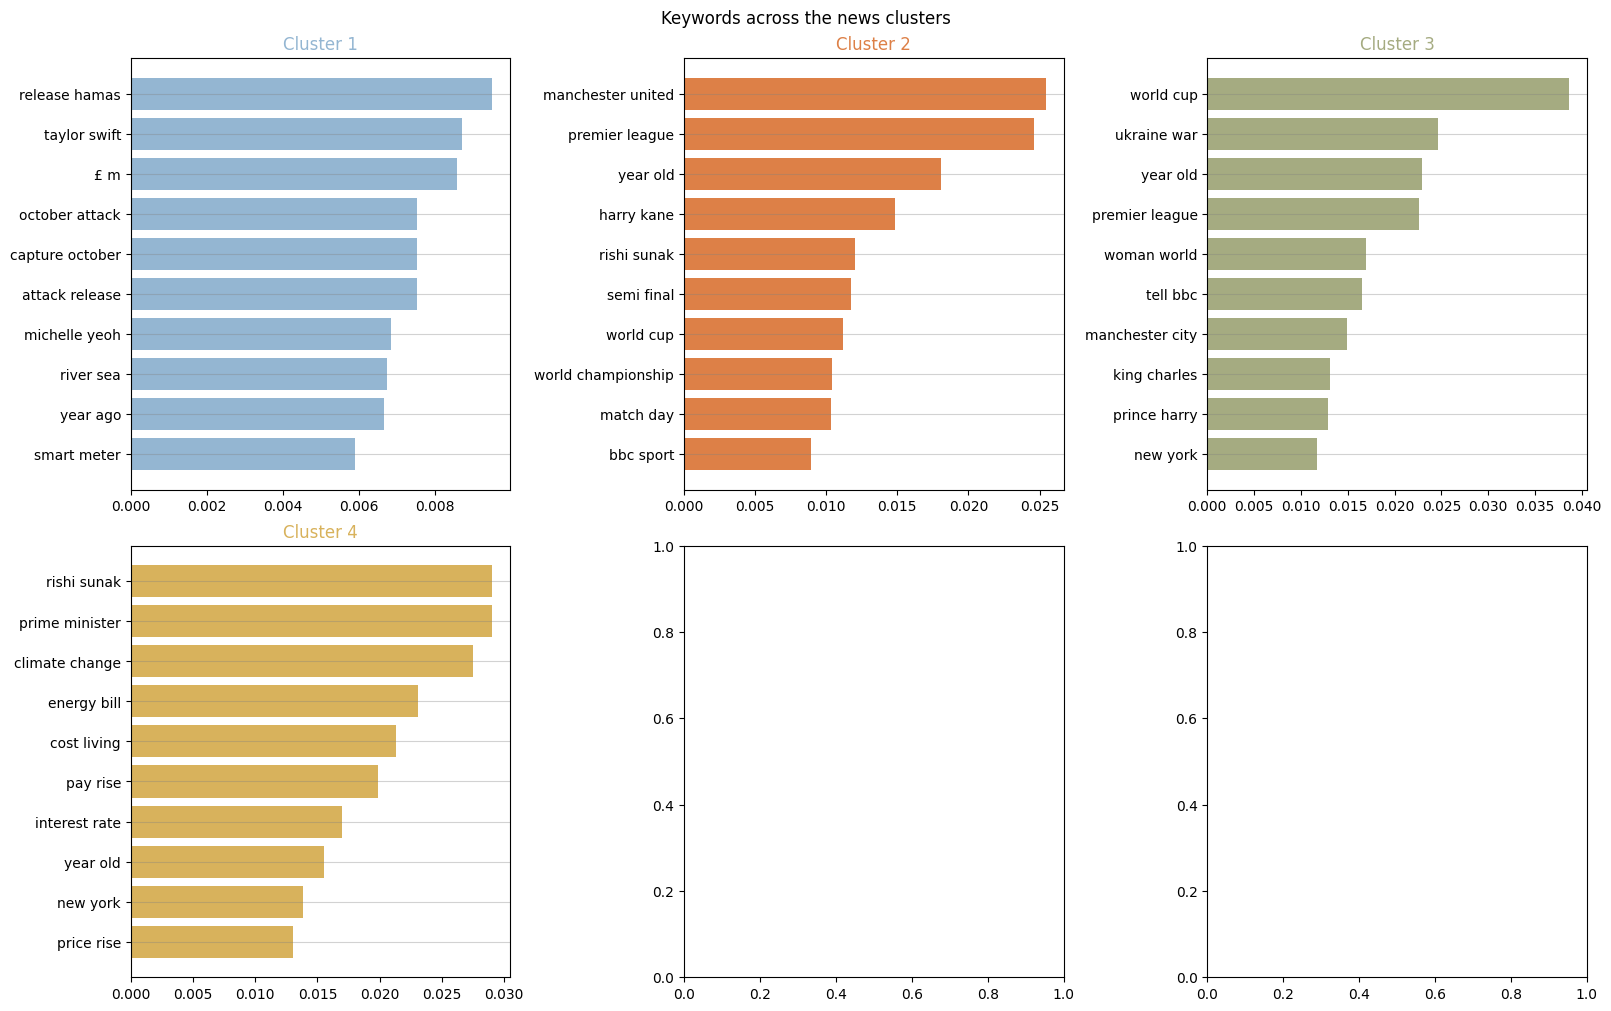

In [109]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = df['clusteri'].nunique()
for i in range(n_clust):

    scored_kwds = getkeyweards(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)


fig.suptitle("Keywords across the news clusters")

plt.show()